<a href="https://colab.research.google.com/github/arielsharonferdinandus/sentiment_classification/blob/main/sentiment_classification.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Amazon Video Games Reviews — Klasifikasi Sentimen (Macro-F1)

Notebook ini self-contained dan bisa dijalankan **Runtime > Run all** di Google Colab.

**Alur:** (1) Setup → (2) Stream data & filter tanggal/label → (3) Baca bertahap & deduplikasi →
(4) Split temporal → (5) Tuning → (6) Training final → (7) Evaluasi validasi → (8) Simpan & muat ulang model → (9) README otomatis.

**Catatan Colab:** unduhan file mentah Video_Games (~GB) dibaca **per baris via streaming** (tidak disimpan utuh & tidak dimuat ke memori);
hanya kolom yang dibutuhkan dari sampel hasil filter yang ditulis ke `data/filtered_sample.csv` secara bertahap.

## 1. Setup

In [ ]:
%%writefile review_preprocess.py
"""Preprocessing & inference helpers untuk Amazon Video Games sentiment model.

Modul ini HARUS tersedia (satu folder dengan notebook / di PYTHONPATH) saat
memuat file model .joblib, karena pipeline mereferensikan `prepare_texts`.
"""
import re

import pandas as pd

_HTML = re.compile(r"<[^>]+>")
_URL = re.compile(r"https?://\S+|www\.\S+")
_REPEAT = re.compile(r"(.)\1{3,}")
_WS = re.compile(r"\s+")

LABELS = {0: "negative", 1: "positive"}


def clean_text(s):
    """Bersihkan satu string: HTML, URL, karakter berulang, spasi."""
    if s is None or (isinstance(s, float) and s != s):
        return ""
    s = str(s)
    s = _HTML.sub(" ", s)          # <br />, <b>, dst.
    s = _URL.sub(" url ", s)       # URL -> token generik
    s = _REPEAT.sub(r"\1\1\1", s)  # "sooooo" -> "sooo"
    s = _WS.sub(" ", s)
    return s.strip()


def prepare_texts(X):
    """Gabungkan judul + teks ulasan menjadi satu string per baris.

    X: DataFrame dengan kolom 'title' dan 'text'.
    Return: list[str] -> "<judul> . <teks>" (lowercase dilakukan vectorizer).
    """
    if not isinstance(X, pd.DataFrame):
        raise TypeError("X harus DataFrame dengan kolom 'title' dan 'text'")
    titles = X["title"].tolist()
    texts = X["text"].tolist()
    return [f"{clean_text(t)} . {clean_text(x)}" for t, x in zip(titles, texts)]


def predict_sentiment(bundle, titles, texts, return_proba=False):
    """Prediksi sentimen dari bundle hasil joblib.load().

    titles/texts: str tunggal atau list[str].
    Return: list label ('negative'/'positive'); jika return_proba=True,
    tambahan array P(positive).
    """
    if isinstance(titles, str):
        titles = [titles]
    if isinstance(texts, str):
        texts = [texts]
    df = pd.DataFrame({"title": list(titles), "text": list(texts)})
    proba = bundle["pipeline"].predict_proba(df)[:, 1]
    pred = (proba >= bundle["threshold"]).astype(int)
    labels = [LABELS[int(p)] for p in pred]
    return (labels, proba) if return_proba else labels

Writing review_preprocess.py


In [ ]:
import os, json, gzip, time, random, sys
from datetime import datetime, timezone

import numpy as np
import pandas as pd
import requests
import joblib
import matplotlib.pyplot as plt

sys.path.insert(0, os.getcwd())
import review_preprocess as rp

# ------------------------- KONFIGURASI -------------------------
SEED = 42
DATA_URLS = [  # dicoba berurutan; yang pertama berhasil dipakai
    "https://huggingface.co/datasets/McAuley-Lab/Amazon-Reviews-2023/resolve/main/raw/review_categories/Video_Games.jsonl",
    "https://mcauleylab.ucsd.edu/public_datasets/data/amazon_2023/raw/review_categories/Video_Games.jsonl.gz",
]
if os.environ.get("DATA_URL_OVERRIDE"):
    DATA_URLS = [os.environ["DATA_URL_OVERRIDE"]]
LOCAL_PATH = os.environ.get("LOCAL_JSONL")          # opsional: path file .jsonl / .jsonl.gz lokal
SAMPLE_RATE = float(os.environ.get("SAMPLE_RATE", 0.15))  # fraksi baris valid yang disimpan (acak, seed tetap)
MAX_LINES = None                                    # batasi jumlah baris yang dibaca (None = seluruh file)
FORCE_REBUILD = False                               # True = bangun ulang cache sampel
VAL_FRAC = 0.15                                     # porsi terbaru (waktu) untuk validasi
DEV_FRAC = 0.10                                     # porsi terbaru dari train untuk tuning
CHUNK_ROWS = 100_000                                # ukuran chunk tulis/baca
N_FEATURES = 2 ** 21                                # dimensi HashingVectorizer
C_GRID = [0.5, 2.0, 8.0]

CACHE_CSV = "data/filtered_sample.csv"
STATS_JSON = "data/stream_stats.json"
MODEL_PATH = "model/sentiment_model.joblib"
os.makedirs("data", exist_ok=True); os.makedirs("model", exist_ok=True)

# Batas waktu: 31 Des 2019 23:59:59.999 UTC (timestamp dataset dalam milidetik)
CUTOFF_MS = int(datetime(2019, 12, 31, 23, 59, 59, 999000, tzinfo=timezone.utc).timestamp() * 1000)
print("CUTOFF_MS =", CUTOFF_MS)
random.seed(SEED); np.random.seed(SEED)

CUTOFF_MS = 1577836799999


## 2. Pembacaan bertahap (streaming), filter tanggal, pembentukan label

- Dibaca **baris demi baris** (HTTP streaming / file lokal) — file mentah tidak pernah dimuat utuh.
- Filter: `timestamp <= 31 Des 2019`; rating 3 dibuang; rating 1–2 → `0` (negative), 4–5 → `1` (positive).
- Baris valid disampel acak (seed tetap) dengan peluang `SAMPLE_RATE` agar memori terkendali, lalu ditulis ke CSV per chunk.
- Kolom yang disimpan: `title`, `text`, `timestamp`, `label`.

In [ ]:
def iter_lines():
    """Generator baris mentah (bytes) dari file lokal atau streaming HTTP."""
    if LOCAL_PATH:
        opener = gzip.open if LOCAL_PATH.endswith(".gz") else open
        with opener(LOCAL_PATH, "rb") as f:
            for line in f:
                yield line
    else:
        last_err = None
        for url in DATA_URLS:
            try:
                r = requests.get(url, stream=True, timeout=60)
                r.raise_for_status()
            except Exception as e:
                last_err = e; print("Gagal membuka", url, "->", e); continue
            print("Streaming dari:", url)
            with r:
                if url.endswith(".gz"):
                    for line in gzip.GzipFile(fileobj=r.raw):
                        yield line
                else:
                    for line in r.iter_lines(chunk_size=1 << 20):
                        if line:
                            yield line
            return
        raise RuntimeError(f"Semua sumber data gagal: {last_err}")


def build_sample():
    rng = random.Random(SEED)
    stats = dict(lines=0, bad_json=0, missing_fields=0, after_date=0, rating3_dropped=0,
                 valid=0, sampled=0, sampled_neg=0, sampled_pos=0)
    buf, first = [], True
    t0 = time.time()

    def flush():
        nonlocal buf, first
        if buf:
            pd.DataFrame(buf, columns=["title", "text", "timestamp", "label"]).to_csv(
                CACHE_CSV, mode="w" if first else "a", header=first, index=False)
            first, buf = False, []

    for raw in iter_lines():
        stats["lines"] += 1
        if MAX_LINES and stats["lines"] > MAX_LINES:
            break
        try:
            d = json.loads(raw)
        except Exception:
            stats["bad_json"] += 1; continue
        try:
            rating = float(d["rating"]); ts = int(d["timestamp"])
        except Exception:
            stats["missing_fields"] += 1; continue
        if ts < 10**11:          # jaga-jaga jika timestamp dalam detik
            ts *= 1000
        if ts > CUTOFF_MS:
            continue
        stats["after_date"] += 1
        if rating == 3:
            stats["rating3_dropped"] += 1; continue
        if rating in (1.0, 2.0):
            label = 0
        elif rating in (4.0, 5.0):
            label = 1
        else:
            stats["missing_fields"] += 1; continue
        title, text = d.get("title") or "", d.get("text") or ""
        if not (str(title).strip() or str(text).strip()):
            continue
        stats["valid"] += 1
        if rng.random() >= SAMPLE_RATE:
            continue
        stats["sampled"] += 1; stats["sampled_neg" if label == 0 else "sampled_pos"] += 1
        buf.append((title, text, ts, label))
        if len(buf) >= CHUNK_ROWS:
            flush()
        if stats["lines"] % 500_000 == 0:
            print(f"  ...{stats['lines']:,} baris dibaca, {stats['sampled']:,} disimpan, {time.time()-t0:.0f}s")
    flush()
    stats["elapsed_sec"] = round(time.time() - t0, 1)
    json.dump(stats, open(STATS_JSON, "w"), indent=2)
    return stats


if FORCE_REBUILD or not os.path.exists(CACHE_CSV):
    stats = build_sample()
else:
    print("Cache ditemukan, melewati streaming:", CACHE_CSV)
    stats = json.load(open(STATS_JSON))
print(json.dumps(stats, indent=2))

Streaming dari: https://huggingface.co/datasets/McAuley-Lab/Amazon-Reviews-2023/resolve/main/raw/review_categories/Video_Games.jsonl
{
  "lines": 4624615,
  "bad_json": 0,
  "missing_fields": 0,
  "after_date": 3044032,
  "rating3_dropped": 230235,
  "valid": 2813797,
  "sampled": 423207,
  "sampled_neg": 74392,
  "sampled_pos": 348815,
  "elapsed_sec": 60.9
}


## 3. Baca CSV per chunk + deduplikasi

Sampel dibaca kembali **per chunk** (`chunksize`) dan dirakit menjadi DataFrame. Duplikat persis (judul+teks) dibuang
**sebelum** split agar salinan ulasan yang sama tidak bisa berada di train dan validasi sekaligus (sumber data leakage).

In [ ]:
chunks = []
for ch in pd.read_csv(CACHE_CSV, chunksize=CHUNK_ROWS, dtype={"title": "string", "text": "string",
                                                              "timestamp": "int64", "label": "int8"},
                      keep_default_na=False):
    chunks.append(ch)
df = pd.concat(chunks, ignore_index=True); del chunks

n0 = len(df)
df["title"] = df["title"].fillna("").astype(str); df["text"] = df["text"].fillna("").astype(str)
df = df.sort_values("timestamp", kind="stable").reset_index(drop=True)
df = df.drop_duplicates(subset=["title", "text"], keep="first").reset_index(drop=True)   # simpan yang paling awal
print(f"Baris sampel: {n0:,} -> setelah dedup: {len(df):,}")
assert df["timestamp"].max() <= CUTOFF_MS, "Ada ulasan setelah 31 Des 2019!"
assert set(df["label"].unique()) <= {0, 1}
print("Rentang waktu:", pd.to_datetime(df.timestamp.min(), unit="ms"), "->", pd.to_datetime(df.timestamp.max(), unit="ms"))
print(df["label"].map(rp.LABELS).value_counts(normalize=True).round(3))
df.head(3)

Baris sampel: 423,207 -> setelah dedup: 390,659
Rentang waktu: 1998-12-18 00:10:47 -> 2019-12-31 23:59:18.236000
label
positive    0.811
negative    0.189
Name: proportion, dtype: float64


,title,text,timestamp,label
0,Annual must see for Peanuts fans.,"Yes, it's campy. Yes, it has sub-standard anim...",913939847000,1
1,The songs on this soundtrack will brighten up ...,I bought this soundtrack because it had been r...,921257587000,1
2,The Best ST: TNG movie yet,The 1st thing everyone does is compare this mo...,929119529000,1


## 4. Strategi pembagian data: split **temporal** (tanpa leakage)

Ulasan diurutkan menurut waktu: **85% terlama → train, 15% terbaru → validasi**.

Alasan: (1) meniru penggunaan nyata (model dilatih dari ulasan lampau, memprediksi ulasan *baru*); (2) validasi selalu
lebih baru dari train sehingga tidak ada kebocoran informasi dari masa depan, termasuk topik/game/slang yang muncul
bersamaan; (3) validasi **mempertahankan distribusi kelas alami** (tidak di-resample) sehingga Macro-F1 jujur;
(4) duplikat sudah dibuang, dan semua komponen yang "belajar" (idf, tuning C, threshold) hanya melihat data train.

In [ ]:
cut_ts = df["timestamp"].iloc[int(len(df) * (1 - VAL_FRAC))]
train_df = df[df["timestamp"] < cut_ts].reset_index(drop=True)
val_df   = df[df["timestamp"] >= cut_ts].reset_index(drop=True)

# Split dalam (hanya dari train) untuk tuning hyperparameter & threshold -> validasi tidak dipakai untuk tuning
cut_dev = train_df["timestamp"].iloc[int(len(train_df) * (1 - DEV_FRAC))]
inner_tr  = train_df[train_df["timestamp"] < cut_dev].reset_index(drop=True)
inner_dev = train_df[train_df["timestamp"] >= cut_dev].reset_index(drop=True)

# --- Pemeriksaan leakage ---
assert train_df["timestamp"].max() < val_df["timestamp"].min(), "Train dan validasi tumpang tindih waktu"
key = lambda d: set(zip(d["title"], d["text"]))
assert len(key(train_df) & key(val_df)) == 0, "Ada teks identik di train & validasi"
assert len(key(inner_tr) & key(inner_dev)) == 0

def info(name, d):
    print(f"{name:10s} n={len(d):>8,} | {pd.to_datetime(d.timestamp.min(), unit='ms').date()} -> "
          f"{pd.to_datetime(d.timestamp.max(), unit='ms').date()} | neg={np.mean(d.label==0):.3f} pos={np.mean(d.label==1):.3f}")
for n, d in [("train", train_df), ("validasi", val_df), ("inner_tr", inner_tr), ("inner_dev", inner_dev)]:
    info(n, d)
print("Cek leakage: OK")

train      n= 332,060 | 1998-12-18 -> 2019-01-08 | neg=0.190 pos=0.810
validasi   n=  58,599 | 2019-01-08 -> 2019-12-31 | neg=0.181 pos=0.819
inner_tr   n= 298,854 | 1998-12-18 -> 2018-04-27 | neg=0.187 pos=0.813
inner_dev  n=  33,206 | 2018-04-27 -> 2019-01-08 | neg=0.216 pos=0.784
Cek leakage: OK


## 5. Model & tuning

**Model:** `prepare_texts` (gabung `judul . teks`, bersihkan HTML/URL) → `HashingVectorizer` (unigram+bigram, 2²¹ fitur, tanpa kosakata di memori)
→ `TfidfTransformer` (sublinear tf; idf dipelajari dari train saja) → `LogisticRegression(class_weight="balanced")`.

Dipilih karena: cepat & hemat memori untuk jutaan ulasan, baseline kuat untuk sentimen, dapat direproduksi, dan `class_weight="balanced"` +
penyetelan threshold untuk Macro-F1 menjaga performa seimbang di kelas negatif yang minoritas.

Tuning `C` dan threshold dilakukan pada **inner dev** (bagian terbaru dari train). Validasi hanya dipakai sekali untuk pelaporan.

In [ ]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer
from sklearn.feature_extraction.text import HashingVectorizer, TfidfTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score, classification_report, confusion_matrix, precision_recall_fscore_support

TOKEN_PATTERN = r"(?u)\b\w[\w']*\b"

def make_hasher():
    return HashingVectorizer(n_features=N_FEATURES, ngram_range=(1, 2), alternate_sign=False,
                             norm=None, lowercase=True, token_pattern=TOKEN_PATTERN)

def make_pipeline(C):
    return Pipeline([
        ("prep", FunctionTransformer(rp.prepare_texts, validate=False)),
        ("hash", make_hasher()),
        ("tfidf", TfidfTransformer(sublinear_tf=True)),
        ("clf", LogisticRegression(C=C, class_weight="balanced", solver="liblinear", max_iter=200, random_state=SEED)),
    ])

def best_threshold(y, p):
    grid = np.arange(0.20, 0.801, 0.02)
    scores = [f1_score(y, (p >= t).astype(int), average="macro") for t in grid]
    i = int(np.argmax(scores)); return float(grid[i]), float(scores[i])

# HashingVectorizer stateless -> aman dihitung sekali (tidak belajar dari data apa pun)
hasher = make_hasher()
def hash_feats(d): return hasher.transform(rp.prepare_texts(d))

t0 = time.time()
X_itr, X_idev = hash_feats(inner_tr), hash_feats(inner_dev)
y_itr, y_idev = inner_tr["label"].values, inner_dev["label"].values
print(f"Fitur di-hash dalam {time.time()-t0:.0f}s, shape train: {X_itr.shape}")

results = []
for C in C_GRID:
    tf = TfidfTransformer(sublinear_tf=True).fit(X_itr)           # idf hanya dari inner train
    clf = LogisticRegression(C=C, class_weight="balanced", solver="liblinear", max_iter=200,
                             random_state=SEED).fit(tf.transform(X_itr), y_itr)
    p = clf.predict_proba(tf.transform(X_idev))[:, 1]
    f05 = f1_score(y_idev, (p >= 0.5).astype(int), average="macro")
    thr, fbest = best_threshold(y_idev, p)
    results.append(dict(C=C, macroF1_thr0_5=round(f05, 4), best_thr=round(thr, 2), macroF1_best_thr=round(fbest, 4)))
    print(results[-1])
tuning = pd.DataFrame(results)
best = tuning.sort_values("macroF1_best_thr", ascending=False).iloc[0]
BEST_C, BEST_THR = float(best["C"]), float(best["best_thr"])
print(f"\nTerpilih: C={BEST_C}, threshold={BEST_THR}")
del X_itr, X_idev

Fitur di-hash dalam 53s, shape train: (298854, 2097152)
{'C': 0.5, 'macroF1_thr0_5': 0.9298, 'best_thr': 0.4, 'macroF1_best_thr': 0.9379}
{'C': 2.0, 'macroF1_thr0_5': 0.9395, 'best_thr': 0.38, 'macroF1_best_thr': 0.9443}
{'C': 8.0, 'macroF1_thr0_5': 0.9455, 'best_thr': 0.48, 'macroF1_best_thr': 0.9463}

Terpilih: C=8.0, threshold=0.48


## 6. Training final (seluruh data train)

In [ ]:
t0 = time.time()
final_pipe = make_pipeline(BEST_C)
final_pipe.fit(train_df[["title", "text"]], train_df["label"].values)
print(f"Training selesai dalam {time.time()-t0:.0f}s")

Training selesai dalam 150s


## 7. Evaluasi pada data validasi

==> MACRO-F1 VALIDASI = 0.9405   (threshold 0.48)
    sebagai pembanding, threshold 0.50: 0.9399

              precision    recall  f1-score   support

    negative     0.8768    0.9313    0.9032     10630
    positive     0.9846    0.9710    0.9777     47969

    accuracy                         0.9638     58599
   macro avg     0.9307    0.9512    0.9405     58599
weighted avg     0.9650    0.9638    0.9642     58599



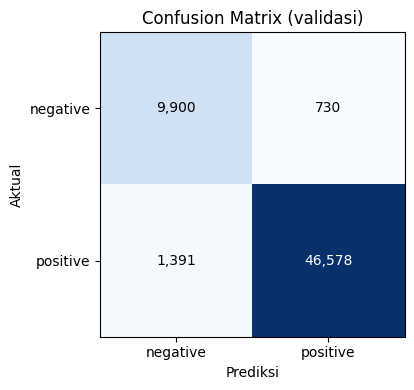

In [ ]:
y_val = val_df["label"].values
p_val = final_pipe.predict_proba(val_df[["title", "text"]])[:, 1]
y_pred = (p_val >= BEST_THR).astype(int)

macro_f1 = f1_score(y_val, y_pred, average="macro")
macro_f1_05 = f1_score(y_val, (p_val >= 0.5).astype(int), average="macro")
prec, rec, f1, sup = precision_recall_fscore_support(y_val, y_pred, labels=[0, 1])

print(f"==> MACRO-F1 VALIDASI = {macro_f1:.4f}   (threshold {BEST_THR:.2f})")
print(f"    sebagai pembanding, threshold 0.50: {macro_f1_05:.4f}\n")
print(classification_report(y_val, y_pred, target_names=["negative", "positive"], digits=4))

cm = confusion_matrix(y_val, y_pred, labels=[0, 1])
fig, ax = plt.subplots(figsize=(4.5, 4))
ax.imshow(cm, cmap="Blues")
ax.set_xticks([0, 1], ["negative", "positive"]); ax.set_yticks([0, 1], ["negative", "positive"])
ax.set_xlabel("Prediksi"); ax.set_ylabel("Aktual"); ax.set_title("Confusion Matrix (validasi)")
for i in range(2):
    for j in range(2):
        ax.text(j, i, f"{cm[i, j]:,}", ha="center", va="center",
                color="white" if cm[i, j] > cm.max() / 2 else "black")
plt.tight_layout(); plt.savefig("model/confusion_matrix.png", dpi=120); plt.show()

metrics = dict(
    macro_f1_val=round(float(macro_f1), 4), macro_f1_val_threshold_0_5=round(float(macro_f1_05), 4),
    threshold=BEST_THR, C=BEST_C,
    per_class={name: dict(precision=round(float(prec[i]), 4), recall=round(float(rec[i]), 4),
                          f1=round(float(f1[i]), 4), support=int(sup[i]))
               for i, name in enumerate(["negative", "positive"])},
    confusion_matrix=cm.tolist(),
    n_train=int(len(train_df)), n_val=int(len(val_df)),
    train_range=[str(pd.to_datetime(train_df.timestamp.min(), unit="ms").date()), str(pd.to_datetime(train_df.timestamp.max(), unit="ms").date())],
    val_range=[str(pd.to_datetime(val_df.timestamp.min(), unit="ms").date()), str(pd.to_datetime(val_df.timestamp.max(), unit="ms").date())],
    sample_rate=SAMPLE_RATE,
)
json.dump(metrics, open("model/metrics.json", "w"), indent=2)

## 8. Simpan model & uji muat ulang (tanpa training ulang)

In [ ]:
import sklearn
bundle = dict(pipeline=final_pipe, threshold=BEST_THR, labels=rp.LABELS,
              meta=dict(sklearn_version=sklearn.__version__, C=BEST_C, n_features=N_FEATURES,
                        macro_f1_val=metrics["macro_f1_val"], seed=SEED))
joblib.dump(bundle, MODEL_PATH, compress=3)
print(f"Model disimpan: {MODEL_PATH} ({os.path.getsize(MODEL_PATH)/1e6:.1f} MB)")

# 1) muat ulang di proses ini & pastikan prediksi identik
loaded = joblib.load(MODEL_PATH)
sub = val_df.head(2000)
lab_loaded = rp.predict_sentiment(loaded, sub["title"].tolist(), sub["text"].tolist())
lab_orig = [rp.LABELS[int(v)] for v in (final_pipe.predict_proba(sub[["title", "text"]])[:, 1] >= BEST_THR)]
assert lab_loaded == lab_orig, "Prediksi model termuat berbeda!"
print("Prediksi model termuat identik dengan model asli: OK")

# 2) muat ulang di interpreter BARU (membuktikan tidak perlu training ulang)
import subprocess, textwrap
snippet = textwrap.dedent("""
    import joblib, review_preprocess as rp
    b = joblib.load("model/sentiment_model.joblib")
    print(rp.predict_sentiment(b, ["Great game!", "Total waste of money"],
          ["Amazing graphics and super fun to play.", "Crashes constantly and the controls are awful."]))
""")
print(subprocess.run([sys.executable, "-c", snippet], capture_output=True, text=True, cwd=os.getcwd()))

# Contoh pemakaian
ex_t = ["Love it", "Broken on arrival", "It's okay"]
ex_x = ["Best game I have played this year, highly recommend!", "Disc was scratched and the game freezes. Want a refund.", "Decent story but a bit repetitive."]
for t, x, l, p in zip(ex_t, ex_x, *rp.predict_sentiment(loaded, ex_t, ex_x, return_proba=True)):
    print(f"{l:8s} P(pos)={p:.3f} | {t}")

Model disimpan: model/sentiment_model.joblib (15.3 MB)
Prediksi model termuat identik dengan model asli: OK
CompletedProcess(args=['/usr/bin/python3', '-c', '\nimport joblib, review_preprocess as rp\nb = joblib.load("model/sentiment_model.joblib")\nprint(rp.predict_sentiment(b, ["Great game!", "Total waste of money"],\n      ["Amazing graphics and super fun to play.", "Crashes constantly and the controls are awful."]))\n'], returncode=0, stdout="['positive', 'negative']\n", stderr='')
positive P(pos)=1.000 | Love it
negative P(pos)=0.000 | Broken on arrival
positive P(pos)=0.949 | It's okay
